# INF5103 — Devoir I : Analyse statistique de quatre jeux de données

**Nom :** *LELE SIMO ELISEE BERTRAND* — **Session :** Automne 2026

**Instructions d'exécution :** placer les quatre fichiers CSV dans le même dossier que ce notebook, puis exécuter toutes les cellules dans l'ordre (*Kernel → Restart & Run All*).

**Déclaration d'usage de l'IA :** *Claude (Anthropic) : génération d’une partie du code Python; correction du français et reformulation de certains commentaires. Les analyses, interprétations et conclusions sont les miennes.*

## 0. Préparation

Importation des bibliothèques, réglages d'affichage et chargement des quatre fichiers (chemins relatifs).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Réglages d'affichage
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.3,
})
# Les fichiers commencent par un BOM : encoding="utf-8-sig" évite un nom de colonne faussé.
df1 = pd.read_csv("plateforme_apprentissage.csv", encoding="utf-8-sig")
df2 = pd.read_csv("consommation_batiment.csv", encoding="utf-8-sig")
df3 = pd.read_csv("dossiers_patients.csv", encoding="utf-8-sig")
df4 = pd.read_csv("latence_service.csv", encoding="utf-8-sig")

for nom, d in [("Jeu 1 - plateforme", df1), ("Jeu 2 - consommation", df2),
               ("Jeu 3 - patients", df3), ("Jeu 4 - latence", df4)]:
    print(f"{nom:<22} : {d.shape[0]:>5} lignes x {d.shape[1]} colonnes")

Jeu 1 - plateforme     :  2400 lignes x 8 colonnes
Jeu 2 - consommation   :  1095 lignes x 6 colonnes
Jeu 3 - patients       :   800 lignes x 7 colonnes
Jeu 4 - latence        :  5000 lignes x 4 colonnes


---
## 1. Jeu 1 — Plateforme d'apprentissage en ligne

**Démarche :**

> *Dans cette section, nous allons comparer l'efficacité des méthodes pédagogiques A et B afin de recommander la meilleure à la direction. Nous analyserons d'abord le taux de réussite global, puis nous détaillerons les résultats par niveau initial et par région afin de vérifier si le profil des apprenants influence les scores. Cette double approche par sous-groupes est indispensable pour détecter un éventuel effet de structure et garantir une conclusion statistiquement fiable.*

### 1.0 Aperçu des données

In [2]:
# Ordre logique des niveaux (utilisé dans tous les tableaux et graphiques)
ORDRE_NIVEAUX = ["débutant", "intermédiaire", "avancé"]
df1["niveau_initial"] = pd.Categorical(df1["niveau_initial"], categories=ORDRE_NIVEAUX, ordered=True)

print("Valeurs manquantes :", int(df1.isna().sum().sum()))
print("Doublons d'identifiant :", int(df1["id_apprenant"].duplicated().sum()))
print()
print("Effectifs par méthode :")
print(df1["methode"].value_counts().sort_index())
print()
print("Effectifs par niveau initial :")
print(df1["niveau_initial"].value_counts().sort_index())
df1.head()

Valeurs manquantes : 0
Doublons d'identifiant : 0

Effectifs par méthode :
methode
A    1200
B    1200
Name: count, dtype: int64

Effectifs par niveau initial :
niveau_initial
débutant         1020
intermédiaire     360
avancé           1020
Name: count, dtype: int64


,id_apprenant,methode,niveau_initial,score_final,reussite,age,region,heures_etude
0,AP0001,B,intermédiaire,70.6,1,38,Québec,28.1
1,AP0002,B,débutant,52.5,0,32,Outaouais,21.9
2,AP0003,A,avancé,56.2,0,21,Hors Québec,23.5
3,AP0004,A,avancé,70.5,1,36,Outaouais,17.8
4,AP0005,B,débutant,81.7,1,33,Québec,29.3


### 1.1 Taux de réussite global par méthode

In [3]:
q1 = (df1.groupby("methode")["reussite"]
         .agg(effectif="count", reussites="sum", taux="mean"))
q1["taux (%)"] = (100 * q1["taux"]).round(1)
q1 = q1.drop(columns="taux")
print(q1)

ecart_global = q1.loc["A", "taux (%)"] - q1.loc["B", "taux (%)"]
print(f"\nÉcart global (A - B) : {ecart_global:+.1f} points de pourcentage")

         effectif  reussites  taux (%)
methode                               
A            1200        844      70.3
B            1200        541      45.1

Écart global (A - B) : +25.2 points de pourcentage


> *En se basant uniquement sur le taux de reussite globale, je recommanderais d'utiliser la methode d'apprentssage A qui obtient un taux de reussite plus eleve (+25.2 %)*

### 1.2 Taux de réussite par méthode à l'intérieur de chaque niveau initial

In [4]:
# Taux de réussite (%) par niveau et par méthode
taux_niveau = (100 * pd.crosstab(df1["niveau_initial"], df1["methode"],
                                 values=df1["reussite"], aggfunc="mean")).round(2)
taux_niveau["écart A - B"] = taux_niveau["A"] - taux_niveau["B"]

# Effectifs correspondants
eff_niveau = pd.crosstab(df1["niveau_initial"], df1["methode"], margins=True, margins_name="Total")

print("Taux de réussite (%) :")
print(taux_niveau)
print("\nEffectifs :")
print(eff_niveau)

Taux de réussite (%) :
methode             A      B  écart A - B
niveau_initial                           
débutant        16.67  36.02       -19.35
intermédiaire   43.89  67.78       -23.89
avancé          80.65  93.33       -12.68

Effectifs :
methode            A     B  Total
niveau_initial                   
débutant          90   930   1020
intermédiaire    180   180    360
avancé           930    90   1020
Total           1200  1200   2400


In [5]:
# Tableau combiné
tableau_q2 = pd.DataFrame({
    m: taux_niveau[m].map("{:.1f} %".format) + " (n = " + eff_niveau.loc[ORDRE_NIVEAUX, m].astype(str) + ")"
    for m in ["A", "B"]
})
tableau_q2.loc["Global"] = [f"{q1.loc[m, 'taux (%)']:.1f} % (n = {q1.loc[m, 'effectif']})" for m in ["A", "B"]]
tableau_q2

,A,B
niveau_initial,,
débutant,16.7 % (n = 90),36.0 % (n = 930)
intermédiaire,43.9 % (n = 180),67.8 % (n = 180)
avancé,80.7 % (n = 930),93.3 % (n = 90)
Global,70.3 % (n = 1200),45.1 % (n = 1200)


> *En observant le tableau, on remarque que en calculant le taux de reussite pour chaque methode d'apprentissage par niveau_initial, que les pourcentage obtenus par les apprenant ayant suivi la methodes B sont plus eleve que ceux ayant suivi la methode A*

### 1.3 Confrontation des questions 1 et 2 : rôle des effectifs

In [6]:
# Répartition des apprenants de chaque méthode entre les niveaux (en % de la colonne)
repartition = (100 * pd.crosstab(df1["niveau_initial"], df1["methode"], normalize="columns")).round(2)
print("Répartition des niveaux à l'intérieur de chaque méthode (%) :")
print(repartition)

# Taux de réussite de chaque niveau, toutes méthodes confondues
taux_par_niveau_tous = (100 * df1.groupby("niveau_initial", observed=True)["reussite"].mean()).round(2)
print("\nTaux de réussite par niveau, toutes méthodes confondues (%) :")
print(taux_par_niveau_tous)

Répartition des niveaux à l'intérieur de chaque méthode (%) :
methode            A     B
niveau_initial            
débutant         7.5  77.5
intermédiaire   15.0  15.0
avancé          77.5   7.5

Taux de réussite par niveau, toutes méthodes confondues (%) :
niveau_initial
débutant         34.31
intermédiaire    55.83
avancé           81.76
Name: reussite, dtype: float64


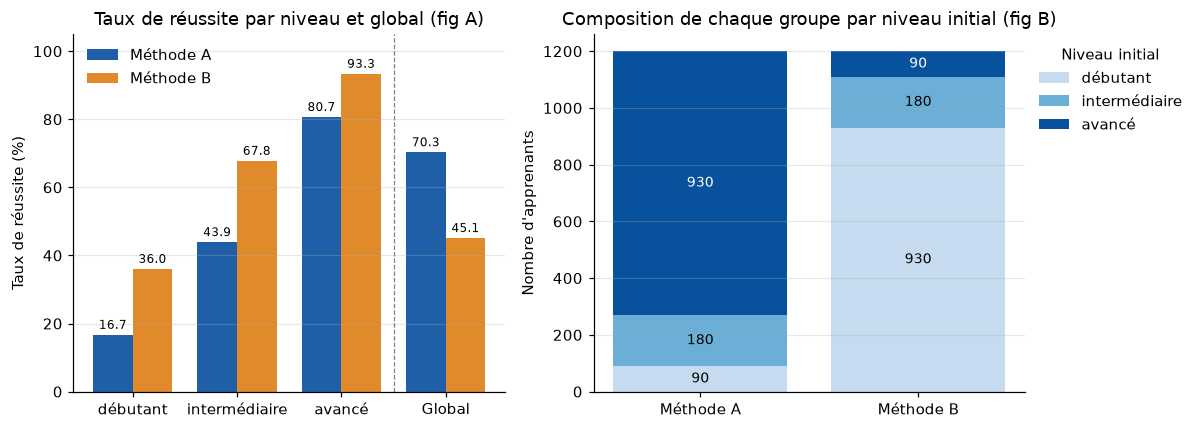

In [7]:
# Figure : (gauche) taux par niveau et par méthode ; (droite) composition de chaque méthode
couleurs = {"A": "#1f5fa8", "B": "#e08a2c"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Gauche : barres groupées des taux de réussite
x = np.arange(len(ORDRE_NIVEAUX) + 1)
largeur = 0.38
etiquettes = ORDRE_NIVEAUX + ["Global"]
for i, m in enumerate(["A", "B"]):
    valeurs = list(taux_niveau[m]) + [q1.loc[m, "taux (%)"]]
    barres = axes[0].bar(x + (i - 0.5) * largeur, valeurs, largeur, label=f"Méthode {m}", color=couleurs[m])
    axes[0].bar_label(barres, fmt="%.1f", fontsize=8, padding=2)
axes[0].axvline(len(ORDRE_NIVEAUX) - 0.5, color="grey", lw=0.8, ls="--")
axes[0].set_xticks(x, etiquettes)
axes[0].set_ylabel("Taux de réussite (%)")
axes[0].set_ylim(0, 105)
axes[0].set_title("Taux de réussite par niveau et global (fig A)")
axes[0].legend(frameon=False)

# Droite : barres empilées de la composition (effectifs) de chaque méthode
bas = np.zeros(2)
teintes = ["#c6dbef", "#6baed6", "#08519c"]
for niv, t in zip(ORDRE_NIVEAUX, teintes):
    vals = eff_niveau.loc[niv, ["A", "B"]].values
    axes[1].bar(["Méthode A", "Méthode B"], vals, bottom=bas, color=t, label=niv)
    for j, v in enumerate(vals):
        axes[1].text(j, bas[j] + v / 2, str(v), ha="center", va="center", fontsize=9,
                     color="white" if niv == "avancé" else "black")
    bas += vals
axes[1].set_ylabel("Nombre d'apprenants")
axes[1].set_title("Composition de chaque groupe par niveau initial (fig B)")
axes[1].legend(title="Niveau initial", frameon=False, bbox_to_anchor=(1, 1), loc="upper left")

fig.tight_layout()
fig.savefig("fig_jeu1.png", dpi=200, bbox_inches="tight")
plt.show()

> *Les résultats globaux et les résultats par niveau initial mènent à des conclusions différentes. Si l'on se base uniquement sur le taux global de réussite, la méthode A devrait être recommandée comme méthode de référence. Cependant, en examinant les taux de réussite par niveau initial (fig. A), on constate que, pour chaque niveau, le taux de réussite de la méthode B est plus élevé que celui de la méthode A, même si la figure B montre que les deux méthodes ont le même effectif total. La différence provient d'un déséquilibre majeur dans l'affectation des apprenants (fig. B). La méthode A a testé une immense majorité d'élèves de niveau avancé (77,5 % de son groupe), qui ont naturellement un taux de réussite très élevé(80.7, 93.3). À l'inverse, la méthode B a été testée sur une majorité de débutants (77,5 %). Le taux global brut est donc  biaisé par la composition des groupes.*

### 1.4 Taux global standardisé (pondération par les effectifs de l'ensemble du groupe)

Pour chaque méthode : taux standardisé = Σ (taux de réussite de la méthode dans le niveau × part de ce niveau dans l'ensemble des apprenants).

In [8]:
# Poids : part de chaque niveau dans l'ensemble des 2400 apprenants (méthodes confondues)
poids = df1["niveau_initial"].value_counts(normalize=True).reindex(ORDRE_NIVEAUX)
print("Poids utilisés (part de chaque niveau dans l'ensemble) :")
print(poids.round(4))

# Taux standardisé de chaque méthode
taux_std = {m: (taux_niveau[m] * poids).sum() for m in ["A", "B"]}

q4 = pd.DataFrame({
    "taux brut (%)": q1["taux (%)"],
    "taux standardisé (%)": pd.Series(taux_std).round(1),
})
print()
print(q4)
print(f"\nÉcart standardisé (A - B) : {taux_std['A'] - taux_std['B']:+.1f} points de pourcentage")

Poids utilisés (part de chaque niveau dans l'ensemble) :
niveau_initial
débutant         0.425
intermédiaire    0.150
avancé           0.425
Name: proportion, dtype: float64

   taux brut (%)  taux standardisé (%)
A           70.3                  47.9
B           45.1                  65.1

Écart standardisé (A - B) : -17.2 points de pourcentage


> *En calculant le taux de reussite pour chaque methode par niveau_initial  en pondérant cette fois les taux par
niveau par les effectifs de l’ensemble du groupe, on voit que les resultats obtenu apres standardisation sont nettement differents de ceux obtenu dans la section 1.1. Le taux brut initialement avantageux pour la méthode A (70,3 % contre 45,1 % pour B) tombe à un taux standardisé de 47,9 %. À l'inverse, le taux de réussite standardisé de la méthode B grimpe à 65,1 %, soit un gain net de +17,2 points de pourcentage en faveur de la méthode B. Ainsi, je recommanderais d'opter la methode d'apprentissage B.*

### 1.5 Même démarche avec une autre variable

Comparaison par variable region. Les variables numériques sont découpées en quatre classes d'effectifs égaux (quartiles).

In [9]:
VARIABLE_Q5 = "region"  

def comparer_par(df, colonne, n_classes=4):
    """Taux de réussite par méthode à l'intérieur de chaque classe de `colonne`,
    avec les effectifs et la répartition de chaque méthode entre les classes."""
    d = df.copy()
    if pd.api.types.is_numeric_dtype(d[colonne]):
        d["classe"] = pd.qcut(d[colonne], q=n_classes)
    else:
        d["classe"] = d[colonne]

    taux = (100 * pd.crosstab(d["classe"], d["methode"],
                              values=d["reussite"], aggfunc="mean")).round(1)
    taux["écart A - B"] = taux["A"] - taux["B"]
    effectifs = pd.crosstab(d["classe"], d["methode"], margins=True, margins_name="Total")
    repart = (100 * pd.crosstab(d["classe"], d["methode"], normalize="columns")).round(1)
    return taux, effectifs, repart

taux_q5, eff_q5, rep_q5 = comparer_par(df1, VARIABLE_Q5)
print(f"Variable : {VARIABLE_Q5}\n")
print("Taux de réussite (%) par classe et par méthode :")
print(taux_q5)
print("\nEffectifs :")
print(eff_q5)
print("\nRépartition des classes à l'intérieur de chaque méthode (%) :")
print(rep_q5)

Variable : region

Taux de réussite (%) par classe et par méthode :
methode         A     B  écart A - B
classe                              
Hors Québec  69.5  44.0         25.5
Montréal     68.2  46.5         21.7
Outaouais    69.5  44.9         24.6
Québec       74.5  44.9         29.6

Effectifs :
methode         A     B  Total
classe                        
Hors Québec   341   309    650
Montréal      302   303    605
Outaouais     282   263    545
Québec        275   325    600
Total        1200  1200   2400

Répartition des classes à l'intérieur de chaque méthode (%) :
methode         A     B
classe                 
Hors Québec  28.4  25.8
Montréal     25.2  25.2
Outaouais    23.5  21.9
Québec       22.9  27.1


In [10]:
# Pour la comparaison avec la question 2 : écarts A - B côte à côte
comparaison = pd.concat({
    "niveau_initial (Q2)": taux_niveau["écart A - B"],
    f"{VARIABLE_Q5} (Q5)": taux_q5["écart A - B"],
}, axis=0).to_frame("écart A - B (points)")
comparaison

écart A - B (points)
niveau_initial (Q2) débutant                     -19.35
                    intermédiaire                -23.89
                    avancé                       -12.68
region (Q5)         Hors Québec                   25.50
                    Montréal                      21.70
                    Outaouais                     24.60
                    Québec                        29.60

> *pour chaque région sans exception (Hors Québec, Montréal, Outaouais, Québec), la méthode A surpasse systématiquement la méthode B, avec un écart positif stable oscillant entre +21,7 et +29,6 points de pourcentage. L'écart global brut de la question 1 (+25,2 points en faveur de A) se reflète de manière homogène dans chaque région. Etant donnes que les ecarts entre les personnes ayant suivi les methodes A et B par rapport a la region geographique sont en accord avec ceux obtenu a la section 1.1, on peut conclure que la variable region n'a aucune consequence sur l'efficacite relatif des methodes d'enseignement*

---
## 2. Jeu 2 — Consommation électrique d'un immeuble de bureaux

**Démarche :**

> *La démarche vise à analyser la relation entre la température  et la consommation énergétique d'un bâtiment à l'aide d'un coefficient de corrélation global, d'un nuage de points segmenté par seuil thermique et d'une vérification des variables du calendrier (occupation et jours fériés) pour isoler les facteurs explicatifs.*

### 2.0 Aperçu des données

In [11]:
# Conversion de la date et création d'un « type de jour » (utile pour les graphiques)
df2["date"] = pd.to_datetime(df2["date"])
df2["fin_semaine"] = df2["jour_semaine"].isin(["samedi", "dimanche"])
df2["type_jour"] = np.where(df2["jour_ferie"] == 1, "férié",
                   np.where(df2["fin_semaine"], "fin de semaine", "jour ouvrable"))

print("Période couverte :", df2["date"].min().date(), "au", df2["date"].max().date())
print("Valeurs manquantes :", int(df2.isna().sum().sum()))
print("\nNombre de jours par type :")
print(df2["type_jour"].value_counts())
df2[["temperature_c", "occupation_pct", "consommation_kwh"]].describe().round(1)

Période couverte : 2023-01-01 au 2025-12-30
Valeurs manquantes : 0

Nombre de jours par type :
type_jour
jour ouvrable     770
fin de semaine    310
férié              15
Name: count, dtype: int64


,temperature_c,occupation_pct,consommation_kwh
count,1095.0,1095.0,1095.0
mean,15.5,53.0,854.1
std,9.1,28.0,244.5
min,-4.4,2.0,250.4
25%,7.2,15.9,679.7
50%,15.7,65.8,860.3
75%,23.7,73.6,1033.8
max,35.6,97.8,1679.1


### 2.1 Coefficient de corrélation entre la température exterieure et la consommation

In [12]:
r_global = df2["temperature_c"].corr(df2["consommation_kwh"])   # Pearson par défaut
print(f"Coefficient de corrélation de Pearson (température, consommation) : r = {r_global:.3f}")
print(f"r² = {r_global**2:.3f}")

Coefficient de corrélation de Pearson (température, consommation) : r = 0.012
r² = 0.000


> *La valeur du cofficient de correlation proche de zero indique qu'il n'existe aucune relation linéaire entre la temperature exterieur et la consommation.*

### 2.2 Nuage de points de la consommation en fonction de la température

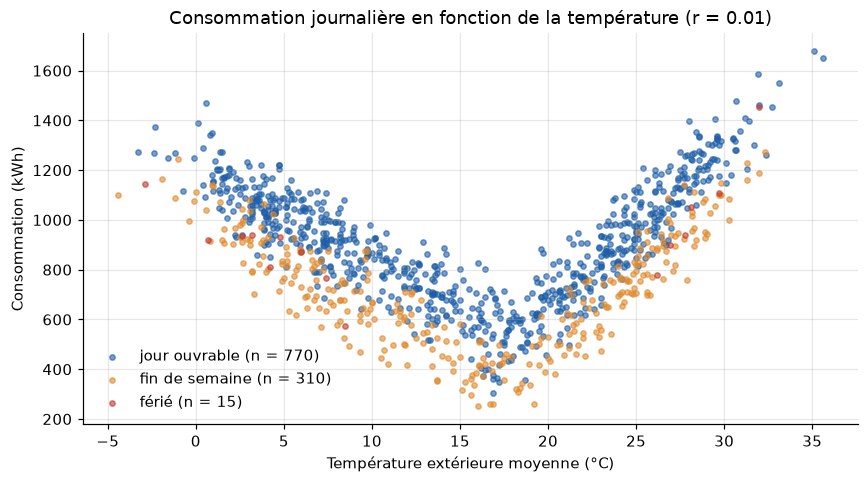

In [13]:
couleurs_jour = {"jour ouvrable": "#1f5fa8", "fin de semaine": "#e08a2c", "férié": "#c0392b"}

fig, ax = plt.subplots(figsize=(8, 4.5))
for type_j, coul in couleurs_jour.items():
    sous = df2[df2["type_jour"] == type_j]
    ax.scatter(sous["temperature_c"], sous["consommation_kwh"], s=12, alpha=0.6,
               color=coul, label=f"{type_j} (n = {len(sous)})")
ax.set_xlabel("Température extérieure moyenne (°C)")
ax.set_ylabel("Consommation (kWh)")
ax.set_title(f"Consommation journalière en fonction de la température (r = {r_global:.2f})")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_q2_2_nuage.png", dpi=200, bbox_inches="tight")
plt.show()

> *La courbe demontre que pour les basse temperature(< 15), plus la temperature diminue, plus la consommation augmente et pour les temperature elevees(>16), plus la temperature augmente, plus la consommation augmente. Ce qui explique pourquoi le coefficient de correlation (Pearson) de la question 2.1 etais proche de zero car il n'est pertinent que dans le cas d'une relation lineaire*

### 2.3 Corrélation dans deux groupes séparés par un seuil de température


In [14]:
SEUIL = 17   

froid = df2[df2["temperature_c"] < SEUIL]
chaud = df2[df2["temperature_c"] >= SEUIL]

r_froid = froid["temperature_c"].corr(froid["consommation_kwh"])
r_chaud = chaud["temperature_c"].corr(chaud["consommation_kwh"])

q3 = pd.DataFrame({
    "nombre de jours": [len(froid), len(chaud), len(df2)],
    "r (température, consommation)": [round(r_froid, 3), round(r_chaud, 3), round(r_global, 3)],
}, index=[f"T < {SEUIL} °C", f"T ≥ {SEUIL} °C", "Toutes les journées (2.1)"])
q3

,nombre de jours,"r (température, consommation)"
T < 17 °C,592,-0.826
T ≥ 17 °C,503,0.884
Toutes les journées (2.1),1095,0.012


> *Le seuil de 17 a ete choisi car il marque le point d'intersection entre les tempeature chaude et froide. La division en deux groupe a permis de faire apparaître des relations linéaires très fortes qui étaient complètement masquées et annulées dans le calcul global de la question 2.1*

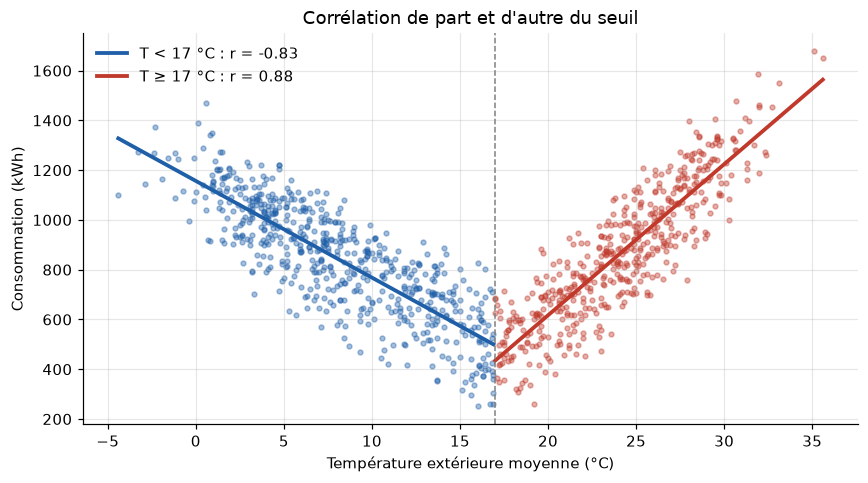

In [15]:
# Figure : representation graphique des droite de regression des deux groupes
fig, ax = plt.subplots(figsize=(8, 4.5))
for groupe, coul, nom in [(froid, "#1f5fa8", f"T < {SEUIL} °C"), (chaud, "#c0392b", f"T ≥ {SEUIL} °C")]:
    ax.scatter(groupe["temperature_c"], groupe["consommation_kwh"], s=10, alpha=0.4, color=coul)
    pente, ordonnee = np.polyfit(groupe["temperature_c"], groupe["consommation_kwh"], 1)
    xs = np.linspace(groupe["temperature_c"].min(), groupe["temperature_c"].max(), 50)
    r = groupe["temperature_c"].corr(groupe["consommation_kwh"])
    ax.plot(xs, pente * xs + ordonnee, color=coul, lw=2.5, label=f"{nom} : r = {r:.2f}")
ax.axvline(SEUIL, color="grey", ls="--", lw=1)
ax.set_xlabel("Température extérieure moyenne (°C)")
ax.set_ylabel("Consommation (kWh)")
ax.set_title("Corrélation de part et d'autre du seuil")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("fig_q2_3_seuil.png", dpi=200, bbox_inches="tight")
plt.show()

> *la projection montre que la relation de part et d'autre du seuil (17 degre celsius)  est linaire*

### 2.4 Température à laquelle la consommation est minimal
approche utilisee : calcul de la consommation moyenne par tranche de 2 °C 

In [16]:
#  Consommation moyenne par tranche de 2 °C
bornes = np.arange(np.floor(df2["temperature_c"].min() / 2) * 2,
                   np.ceil(df2["temperature_c"].max() / 2) * 2 + 2, 2)
df2["tranche_temp"] = pd.cut(df2["temperature_c"], bins=bornes, right=False)
par_tranche = (df2.groupby("tranche_temp", observed=True)["consommation_kwh"]
                  .agg(nb_jours="count", conso_moyenne="mean").round(1))
print(par_tranche)

tranche_min = par_tranche["conso_moyenne"].idxmin()
print(f"\nTranche de consommation moyenne minimale : {tranche_min} "
      f"({par_tranche.loc[tranche_min, 'conso_moyenne']:.1f} kWh, {par_tranche.loc[tranche_min, 'nb_jours']} jours)")

              nb_jours  conso_moyenne
tranche_temp                         
[-6.0, -4.0)         1         1099.1
[-4.0, -2.0)         4         1264.8
[-2.0, 0.0)          9         1160.9
[0.0, 2.0)          44         1146.4
[2.0, 4.0)          77         1022.4
[4.0, 6.0)          86          969.8
[6.0, 8.0)          90          885.7
[8.0, 10.0)         73          798.5
[10.0, 12.0)        54          726.3
[12.0, 14.0)        66          671.2
[14.0, 16.0)        49          585.1
[16.0, 18.0)        70          512.7
[18.0, 20.0)        57          565.2
[20.0, 22.0)        69          667.8
[22.0, 24.0)        79          782.5
[24.0, 26.0)        95          890.8
[26.0, 28.0)        81         1034.4
[28.0, 30.0)        63         1177.2
[30.0, 32.0)        19         1279.5
[32.0, 34.0)         7         1377.2
[34.0, 36.0)         2         1665.3

Tranche de consommation moyenne minimale : [16.0, 18.0) (512.7 kWh, 70 jours)


> *Le tableau montre que au alentours de temperature 16-18 degre, la consommation d'energie est minimale. En comparant ces valeurs avec le nuage produit a la question 2.2, nous observons une forme U montrant que avant  cette tranche de temperature, la consommation croit inversement avec la temperature et apres cette tranche de temperature, la relation est lineairement proportionel. Cela peut s'expliquer physiquement par l'activation du chauffage pour compenser les pertes thermiques lorsque les températures descendent en dessous de ce seuil, et par le démarrage de la climatisation pour évacuer la chaleur et refroidir l'immeuble dès que les températures le dépassent*

### 2.5 Rôle du calendrier d'utilisation : occupation et jours fériés

(a) Part de la variation de la consommation expliquée par occupation_pct et jour_ferie (coefficient de détermination R²).
(b) Lien entre ces variables de calendrier et la température.

In [17]:
# (a) Lien entre le calendrier et la consommation 
r_occ = df2["occupation_pct"].corr(df2["consommation_kwh"])
r_ferie = df2["jour_ferie"].corr(df2["consommation_kwh"])

print(f"Occupation  : r = {r_occ:.3f}   →   R² = {r_occ**2:.3f}")
print(f"Jour férié  : r = {r_ferie:.3f}   →   R² = {r_ferie**2:.3f}")

print("\nConsommation moyenne (kWh) selon le jour férié (0 = non, 1 = oui) :")
print(df2.groupby("jour_ferie")["consommation_kwh"].mean().round(1))



Occupation  : r = 0.358   →   R² = 0.128
Jour férié  : r = 0.042   →   R² = 0.002

Consommation moyenne (kWh) selon le jour férié (0 = non, 1 = oui) :
jour_ferie
0    852.9
1    941.5
Name: consommation_kwh, dtype: float64


                  temperature_c  occupation_pct  jour_ferie  consommation_kwh
temperature_c             1.000          -0.004      -0.023             0.012
occupation_pct           -0.004           1.000      -0.173             0.358
jour_ferie               -0.023          -0.173       1.000             0.042
consommation_kwh          0.012           0.358       0.042             1.000

Température moyenne (°C) selon le jour férié (0 = non, 1 = oui) :
jour_ferie
0    15.5
1    13.7
Name: temperature_c, dtype: float64


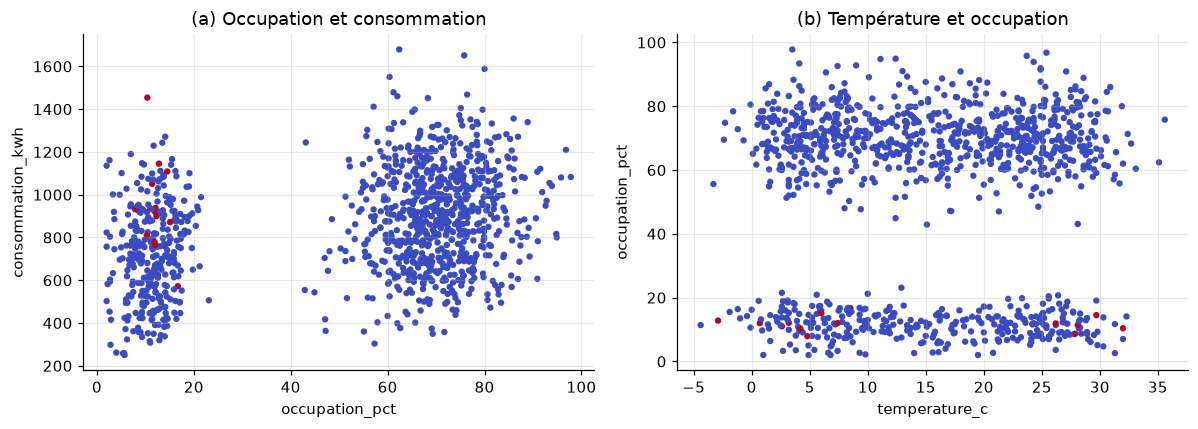

In [18]:
# (b) Matrice de corrélation : chaque case donne le r entre deux colonnes + representation en figure de nuage
colonnes = ["temperature_c", "occupation_pct", "jour_ferie", "consommation_kwh"]
print(df2[colonnes].corr().round(3))

print("\nTempérature moyenne (°C) selon le jour férié (0 = non, 1 = oui) :")
print(df2.groupby("jour_ferie")["temperature_c"].mean().round(1))

# Figure (les points rouges sont les jours fériés.)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df2.plot.scatter(x="occupation_pct", y="consommation_kwh", c="jour_ferie", cmap="coolwarm", colorbar=False, s=10, ax=axes[0], title="(a) Occupation et consommation")
df2.plot.scatter(x="temperature_c", y="occupation_pct", c="jour_ferie", cmap="coolwarm", colorbar=False, s=10, ax=axes[1], title="(b) Température et occupation")
plt.tight_layout()
plt.savefig("fig_q2_5.png", dpi=200)
plt.show()



> *D'après les résultats, le coefficient de corrélation linéaire entre le taux d'occupation et la consommation(r = 0,358, R^2 = 0,128) montre  que le taux d'occupation du batiment  explique 12,8% de la variance de la consommation électrique du bâtiment. Quant à la variable jours fériés, son impact linéaire direct est très faible (r = 0,042, R^2 = 0,002), ce qui s'explique par le fait qu'elle ne représente qu'une petite partie des observations de l'année. La consommation moyenne s'élève à 852,9 kWh les jours normaux contre 941,5 kWh les jours féries.
> La verification de la corelation entre la tempoerature et les variables jours_ferie, occupation nous permets d'ecarter tout biais de confusion. Ainsi on peut voir que la temperature n'est pas corrélée à l'occupation du batiment (r = -0,004)ainsi que les jours fériés  (r = -0,023)*

### 2.6 Bilan sur l'usage du coefficient de corrélation

> *Il est a retenir qu'une valeur de coefficient de correlation entre deux variable proche de zero ne signifie pas forcement que les deux variable n'ont pas de relations. Comme on l'a vu dans la question 2.3, en separant les consommations en deux groupe selon un seuil de temoperature(17), deux droite,une pente négative(temperature basse) et une pente positive (temperature haute), ce qui n'etais pas identifiable dans la resultat obtenu de la question 2.1 (r = 0,012; coefficient de corelation entre les variables brutes de temperature et consommation) qui tendais a nous amener a croire qu'il n'existe pas de relation entre ces deux variable. Il est donc toujours indispensable de tracer un nuage de points avant d'interpréter un coefficient de corrélation, sous peine de passer à côté d'une structure de données non linéaire complexe mais essentielle pour comprendre le phénomène étudié*

---
## 3. Jeu 3 — Dossiers de patients d'une clinique

**Démarche :**

> *L'analyse consiste a initalement decrire statistiquement des données cliniques brutes afin de repérer, quantifier et corriger les anomalies de saisie, les valeurs manquantes masquées et les erreurs d'unités avant d'évaluer l'impact réel de l'âge, de l'IMC, du tabagisme et du sexe sur la tension systolique.*

### 3.0 Aperçu des données brutes

In [19]:
# On conserve une copie intacte des données brutes, pour les comparaisons « avant / après »
df3_brut = df3.copy()

COLS_NUM = ["age", "tension_systolique", "taille_cm", "poids_kg"]

print("Dimensions :", df3_brut.shape)
print("\nTypes des colonnes :")
print(df3_brut.dtypes)
print("\nValeurs manquantes par colonne :")
print(df3_brut.isna().sum())
df3_brut.head()

Dimensions : (800, 7)

Types des colonnes :
id_patient                str
sexe                      str
age                     int64
tension_systolique      int64
taille_cm             float64
poids_kg              float64
tabagisme                 str
dtype: object

Valeurs manquantes par colonne :
id_patient            0
sexe                  0
age                   0
tension_systolique    0
taille_cm             0
poids_kg              0
tabagisme             0
dtype: int64


,id_patient,sexe,age,tension_systolique,taille_cm,poids_kg,tabagisme
0,PT0001,M,61,140,155.3,50.9,ancien
1,PT0002,F,60,136,167.9,74.1,actuel
2,PT0003,F,80,144,179.6,79.4,non
3,PT0004,F,56,121,162.0,72.4,non
4,PT0005,F,59,138,182.1,87.9,ancien


### 3.1 Description statistique et détection des anomalies

Trois étapes : (1) description de chaque colonne numérique (minimum, maximum…) ; (2) vérification des colonnes catégorielles et des doublons ; (3) comptage des valeurs hors d'un intervalle physiologiquement plausible.

In [20]:
# (1) Description de chaque colonne numérique
df3_brut[COLS_NUM].describe().round(2)

,age,tension_systolique,taille_cm,poids_kg
count,800.00,800.00,800.00,800.00
mean,98.63,122.34,164.27,77.24
std,207.25,25.48,33.30,14.55
min,18.00,-1.00,1.54,37.00
25%,41.00,117.00,163.20,67.00
50%,52.00,126.00,170.10,76.25
75%,64.00,135.00,176.42,87.30
max,999.00,164.00,196.70,121.10


> *L'analyse statistique de base a permis de detecter des valeurs anormale; tension systolique invalide (min : -1), taille anormale (min 1.54) selon l'unite de mesure(s'agirait-il d'une erreur de conversion?), valeur age abberante (max a 999)*

In [21]:
# (2) Colonnes catégorielles et doublons
for col in ["sexe", "tabagisme"]:
    print(f"Modalités de « {col} » :")
    print(df3_brut[col].value_counts(dropna=False))
    print()

nb_doublons_id = df3_brut["id_patient"].duplicated().sum()
nb_doublons_hors_id = df3_brut.drop(columns="id_patient").duplicated().sum()
print(f"Identifiants en double                                      : {nb_doublons_id}")
print(f"Lignes identiques sur toutes les colonnes sauf l'identifiant : {nb_doublons_hors_id}")

Modalités de « sexe » :
sexe
F    427
M    373
Name: count, dtype: int64

Modalités de « tabagisme » :
tabagisme
non       500
ancien    186
actuel    114
Name: count, dtype: int64

Identifiants en double                                      : 0
Lignes identiques sur toutes les colonnes sauf l'identifiant : 15


*Une anomalie est détectée (15 lignes identiques sur toutes les colonnes sauf l’identifiant) qui sont très probablement des doublons, le même patient saisi deux fois sous deux numéros*

In [22]:
# (3) Valeurs hors d'un intervalle physiologiquement normale

BORNES = {
    "age":                (0, 120),    # années
    "tension_systolique": (60, 260),   # mmHg
    "taille_cm":          (100, 230),  # cm (adultes)
    "poids_kg":           (25, 300),   # kg
}

lignes = []
for col, (bas, haut) in BORNES.items():
    hors = df3_brut[~df3_brut[col].between(bas, haut)]
    valeurs = sorted(hors[col].unique())
    lignes.append({
        "colonne": col,
        "intervalle plausible": f"[{bas} ; {haut}]",
        "nb lignes hors intervalle": len(hors),
        "valeurs rencontrées (10 premières)": valeurs[:10],
    })
anomalies = pd.DataFrame(lignes).set_index("colonne")
anomalies

,intervalle plausible,nb lignes hors intervalle,valeurs rencontrées (10 premières)
colonne,,,
age,[0 ; 120],40,[999]
tension_systolique,[60 ; 260],25,[-1]
taille_cm,[100 ; 230],30,"[1.54, 1.56, 1.6, 1.63, 1.65, 1.67, 1.68, 1.69..."
poids_kg,[25 ; 300],0,[]


> *En se basant sur mes des connaissance de bases (ex: il est logiquement impossible de trouver un etre humain de 18 ans et plus ayant moins de 1 metre), j'ai fixe des intervalle plausible afin de detecter et quantifier les donnes hors intervalle.*

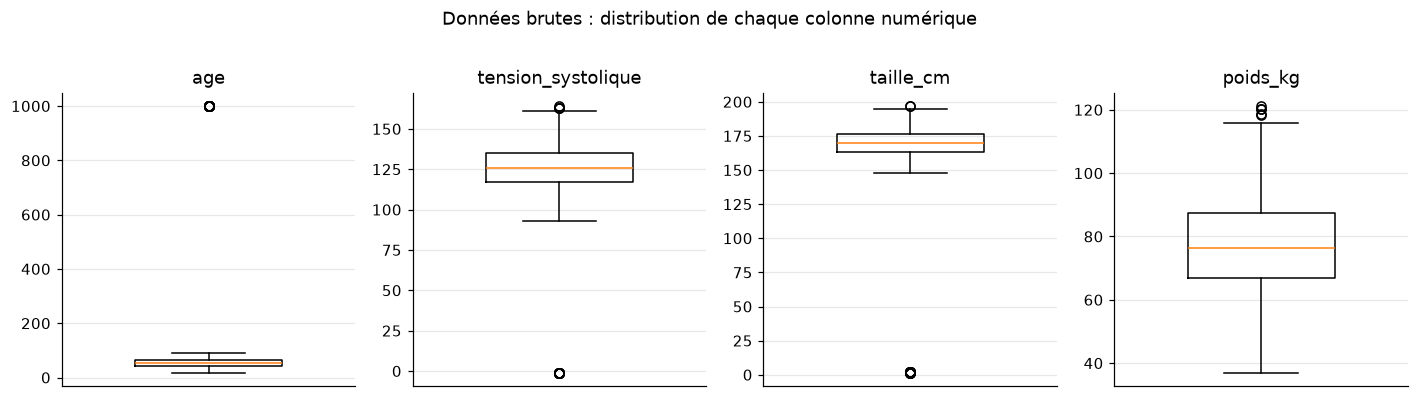

In [23]:
# Figure : boîtes à moustaches des données brutes (isolation des valeurs extremes)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, col in zip(axes, COLS_NUM):
    ax.boxplot(df3_brut[col], widths=0.5)
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Données brutes : distribution de chaque colonne numérique", y=1.02)
fig.tight_layout()
fig.savefig("fig_q3_1_brut.png", dpi=200, bbox_inches="tight")
plt.show()

> *Le box_plot illustre les valeurs aberrantes qui ecrasent les echelles des graphiques. Pour l'age, on voit que la majorite des patient ont un age normal (entre 0 et 200), on peut egalement identifier un point isolé tout en haut, à la valeur 999, ce qui confirme visuellement la présence de cette valeur aberrante. Concernant le plot de la tension_systolique, la distribution est egalement bien centre avec neamoins un point aberrant isolé tout en bas, proche de 0 (qui correspond aux valeurs à -1).  Le graphe de la taille, on observe egalement que  la boîte est bien positionnée autour de 170 cm, mais un point est écrasé tout en bas, proche de 0.Pour le poid en kg, on constate que c'est la seule variable qui presente distribution normal, ce qui appui le fait que nous n'ayons pas trouve de valeurs anormale par rapport au intervalle fixe (40-120 kg).*

### 3.2 Préparation du jeu de données

Traitement des donnees par rapport aux anomalies detecte a la question 3.1 

| Action | Effet |
|---|---|
| `"convertir_m_en_cm"` | pour la taille, multiplier par 100 les tailles inférieures à 3, supposées saisies en mètres |        
| `"retirer"` | pour l'age et tension systolique, supprimer les lignes concernées |
| `"garder"` | pour le poid, ne change rien |

In [24]:
# Préparation : df3 = données brutes (non modifiées), df = données nettoyes
NUM = ["age", "tension_systolique", "taille_cm", "poids_kg"]

df = df3.copy()
df[NUM] = df[NUM].apply(pd.to_numeric, errors="coerce")
journal = []

def consigner(etape, avant, apres):
    journal.append({"étape": etape, "lignes avant": avant, "lignes après": apres,
                    "lignes retirées": avant - apres})

In [25]:
# Étape 1 : changer taille m en cm(pour taille inferieur a 3cm) 
mask_taille = df["taille_cm"] < 3.0
print("Tailles saisies en mètres :", mask_taille.sum())
print("Exemples avant correction :", df.loc[mask_taille, "taille_cm"].head().tolist())

df.loc[mask_taille, "taille_cm"] = df.loc[mask_taille, "taille_cm"] * 100
print("Exemples après correction :", df.loc[mask_taille, "taille_cm"].head().tolist())
consigner(f"Correction taille_cm < 3 (x 100) : {mask_taille.sum()} valeurs corrigées", len(df), len(df))

Tailles saisies en mètres : 30
Exemples avant correction : [1.65, 1.68, 1.87, 1.69, 1.85]
Exemples après correction : [165.0, 168.0, 187.0, 169.0, 185.0]


In [26]:
# Étape 2 : retrait des âges inconnus (code 999)
n = len(df)
print("Lignes avec age = 999 :", (df["age"] == 999).sum())
df = df[df["age"] != 999]
consigner("Retrait des lignes age = 999", n, len(df))

Lignes avec age = 999 : 40


In [27]:
# Étape 3 : retrait des tensions non mesurées (code -1)
n = len(df)
print("Lignes avec tension_systolique = -1 :", (df["tension_systolique"] == -1).sum())
df = df[df["tension_systolique"] != -1]
consigner("Retrait des lignes tension_systolique = -1", n, len(df))

Lignes avec tension_systolique = -1 : 25


In [28]:
# Bilan
pd.DataFrame(journal)

,étape,lignes avant,lignes après,lignes retirées
0,Correction taille_cm < 3 (x 100) : 30 valeurs ...,800,800,0
1,Retrait des lignes age = 999,800,760,40
2,Retrait des lignes tension_systolique = -1,760,735,25


In [29]:
# Bilan sommaire
print(f"Lignes au départ : {len(df3)}")
print(f"Lignes retirées  : {len(df3) - len(df)}")
print(f"Lignes finales   : {len(df)}")

Lignes au départ : 800
Lignes retirées  : 65
Lignes finales   : 735


In [30]:
# Vérification : il ne doit plus rester de valeur codée ou impossible
df[NUM].describe().T

,count,mean,std,min,25%,50%,75%,max
age,735.0,51.200,15.543,18.0,41.0,51.0,61.50,89.0
tension_systolique,735.0,126.369,12.935,93.0,117.0,126.0,135.00,164.0
taille_cm,735.0,170.606,9.112,148.0,164.2,170.7,176.85,196.7
poids_kg,735.0,77.258,14.679,37.0,67.0,76.3,87.30,121.1


> *Nous avons decide de retirer les lignes des variables age et tension_systolique dont certains valeurs etaient aberantes. En partant de l'hypothese qu'il y a eu une erreur dans la conversion, nous avons decide de multiplier par 100 toute valeur inferieur a 3. Ces changements ont resulte en un retrait de 65 lignes.Par ailleurs, concernant les doublons physiologiques détectés en 3.1 (hors identifiant unique), nous avons choisi de les conserver. L'IMC étant calculé uniquement à partir de la taille et du poids, il est statistiquement normal et attendu que plusieurs individus distincts de la population partagent exactement les mêmes mesures corporelles. Supprimer ces lignes reviendrait à fausser la distribution réelle de l'IMC de notre échantillon et à sous-estimer certaines classes de poids.*

### 3.3 Moyenne et médiane de l'âge avant et après la préparation

In [31]:
num_brut = df3[NUM].apply(pd.to_numeric, errors="coerce")   # données brutes, en numérique
q3 = pd.DataFrame({
    "avant": [num_brut["age"].mean(), num_brut["age"].median()],
    "après": [df["age"].mean(), df["age"].median()],
}, index=["moyenne", "médiane"]).round(2)
q3["écart"] = (q3["après"] - q3["avant"]).round(2)
q3

,avant,après,écart
moyenne,98.63,51.2,-47.43
médiane,52.00,51.0,-1.00


> *Le tableau de Bilan de la question 3.2 nous montre que 40 lignes ont ete retire a cause de la variable age, le box plot precedent (3.1) nous avait revele que la valeur abberante correspondait essentiellement a la donnee age=999(ces valeurs causent un ecart entre la moyenne et la medianne  : 46.63), le reste des donnee etant centre s’étendant de 18 à 89 ans, la moitié centrale des patients ayant entre 41 et 61,5 ans. Une elimination de cette valeur aberrante a permis de retrouver une distribution  dont la moyenne et la mediannne sont presque identique(ecart = 0,2).*

### 3.4 Corrélation entre l'âge et la tension systolique, avant et après

In [32]:
r_avant = num_brut["age"].corr(num_brut["tension_systolique"])
r_apres = df["age"].corr(df["tension_systolique"])
print(f"r avant nettoyage : {r_avant:.3f}")
print(f"r après nettoyage : {r_apres:.3f}")

r avant nettoyage : 0.051
r après nettoyage : 0.696


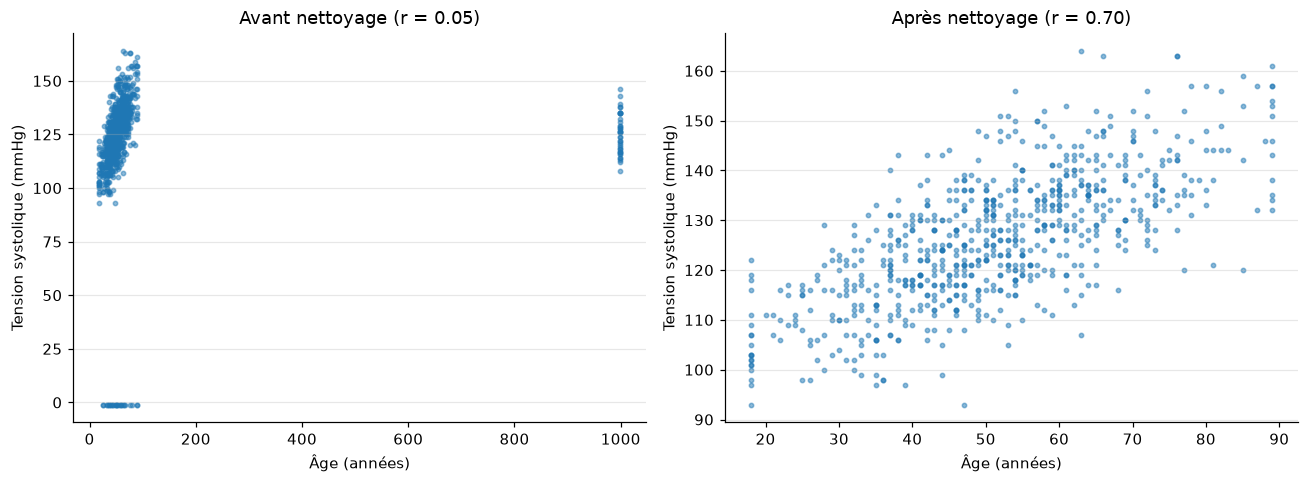

In [33]:
#representation en dotplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(num_brut["age"], num_brut["tension_systolique"], s=8, alpha=0.5)
axes[0].set_title(f"Avant nettoyage (r = {r_avant:.2f})")
axes[1].scatter(df["age"], df["tension_systolique"], s=8, alpha=0.5)
axes[1].set_title(f"Après nettoyage (r = {r_apres:.2f})")
for ax in axes:
    ax.set_xlabel("Âge (années)")
    ax.set_ylabel("Tension systolique (mmHg)")
plt.tight_layout()
plt.savefig("fig_q3_4.png", dpi=200)
plt.show()

> *En analysant les deux dot plot, nous constatons que pour le graphe avant nettoyage (r = 0,05), le coefficient de corrélation étant proche de 0, nous observons une ségrégation  de groupes de points. Cela correspondrait d'une part à la ligne de points aberrants tout en bas (tensions codées à -1) et, d'autre part, au bloc de points rejeté à l'extrême droite (âges codés à 999), deux anomalies de saisie qui masquent complètement la véritable relation entre les deux variable. Quant au graphe apres nettoyage (r=0,70),  nous constatons que la suppression de ces observations aberrantes fait disparaître cette ségrégation artificielle. Les points se regroupent désormais en un seul nuage homogène qui présente une tendance linéaire ascendante très nette. Cette forte hausse du coefficient de corrélation, qui passe de 0,05 à 0,70, confirme que l'élimination des codes d'erreurs réaligne mathématiquement les données avec la réalité clinique : la tension systolique augmente de manière constante et significative à mesure que les patients avancent en âge.  *

### 3.5 Tension systolique moyenne par classe d'IMC

IMC = poids (kg) / taille (m)². D'apres l'Organisation mondiale de la santé : insuffisance pondérale (< 18,5), poids normal (18,5 à 25), surpoids (25 à 30), obésité (≥ 30).

In [34]:
df = df.copy()
df["imc"] = df["poids_kg"] / (df["taille_cm"] / 100) ** 2
df["imc"].describe()

count    735.000
mean      26.493
std        4.272
min       15.980
25%       23.754
50%       26.566
75%       29.386
max       39.624
Name: imc, dtype: float64

In [35]:
# Classes de l'OMS : maigreur < 18,5 ; normal 18,5-25 ; surpoids 25-30 ; obésité >= 30
df["classe_imc"] = pd.cut(df["imc"], bins=[0, 18.5, 25, 30, np.inf], right=False,
                          labels=["maigreur", "normal", "surpoids", "obésité"])
q5 = (df.groupby("classe_imc", observed=False)["tension_systolique"]
        .agg(["count", "mean", "median"]).round(1))
q5

,count,mean,median
classe_imc,,,
maigreur,30,117.6,117.5
normal,224,123.1,122.5
surpoids,330,126.7,126.0
obésité,151,132.2,132.0


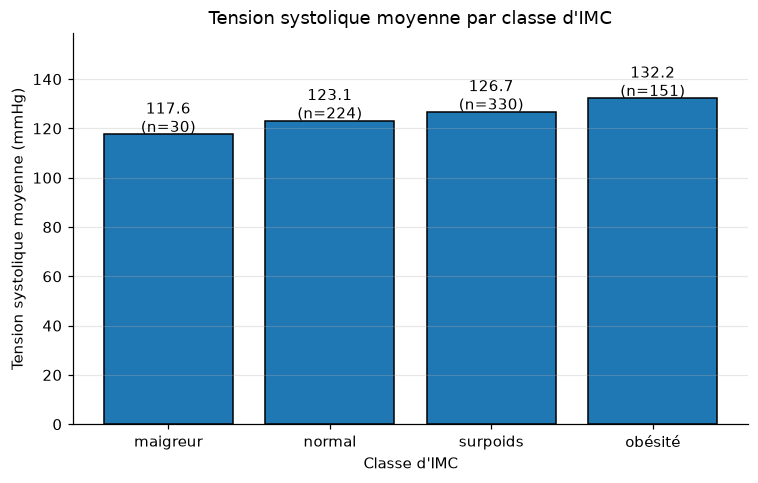

In [36]:
#representation graphique 
plt.figure(figsize=(7, 4.5))
plt.bar(q5.index.astype(str), q5["mean"], edgecolor="black")
for i, (m, c) in enumerate(zip(q5["mean"], q5["count"])):
    plt.text(i, m + 1, f"{m:.1f}\n(n={c})", ha="center")
plt.ylabel("Tension systolique moyenne (mmHg)")
plt.xlabel("Classe d'IMC")
plt.title("Tension systolique moyenne par classe d'IMC")
plt.ylim(0, q5["mean"].max() * 1.2)
plt.tight_layout()
plt.savefig("fig_q3_5.png", dpi=200)
plt.show()

> *le bar plot suivant montre une progression lineaire et continue de la tension systolique moyenne par rapport au classe d'IMC, ce qui confirme un lien fort entre la masse corporelle et la pression arterielle.Le passage d'un IMC normal à un statut d'obésité se traduit par une hausse de tension moyenne d'environ 9,1mmHg, ce qui déplace la moyenne de cette catégorie au-delà du seuil de préhypertension (généralement fixé à 130 mmHg). L'indice de masse corporelle apparaît donc comme un facteur de risque majeur accompagnant une tension élevée au sein des patients.*

### 3.6 Tension systolique selon le statut tabagique et selon le sexe

In [37]:
# Tension moyenne selon le statut tabagique
df.groupby("tabagisme")["tension_systolique"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
tabagisme,,,
actuel,106,132.0,133.0
ancien,172,127.2,128.0
non,457,124.8,124.0


In [38]:
#  Tension moyenne selon le sexe
df.groupby("sexe")["tension_systolique"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
sexe,,,
F,399,126.1,125.0
M,336,126.7,128.0


In [39]:
#  Le chiffre clé : écart entre la moyenne la plus haute et la plus basse
moy_tabac = df.groupby("tabagisme")["tension_systolique"].mean()
moy_sexe = df.groupby("sexe")["tension_systolique"].mean()

print("Écart selon le tabagisme :", round(moy_tabac.max() - moy_tabac.min(), 1), "mmHg")
print("Écart selon le sexe      :", round(moy_sexe.max() - moy_sexe.min(), 1), "mmHg")

Écart selon le tabagisme : 7.3 mmHg
Écart selon le sexe      : 0.7 mmHg


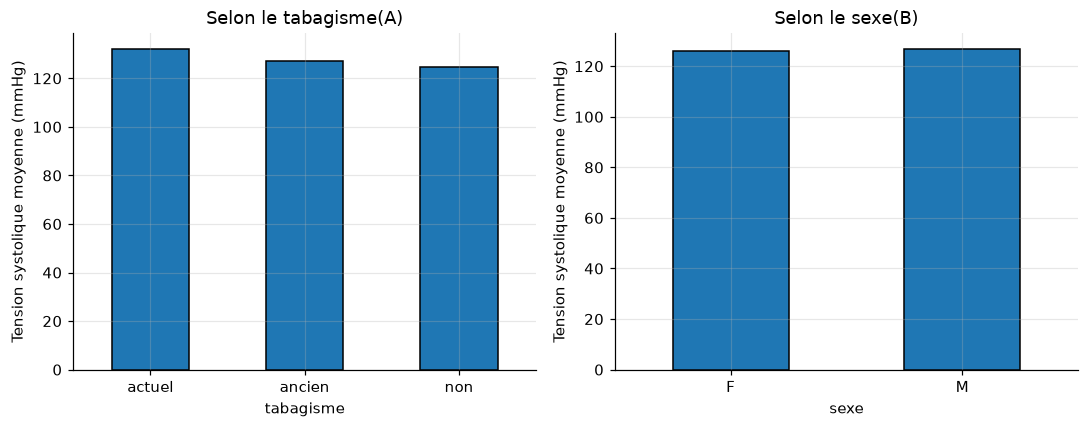

In [40]:
#  Figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
moy_tabac.plot(kind="bar", ax=axes[0], edgecolor="black", title="Selon le tabagisme(A)")
moy_sexe.plot(kind="bar", ax=axes[1], edgecolor="black", title="Selon le sexe(B)")
for ax in axes:
    ax.set_ylabel("Tension systolique moyenne (mmHg)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("fig_q3_6.png", dpi=200)
plt.show()

> *les plots montrent la variation de la tension systolique par rapport au statut de tabagisme(A) et selon le sexe (B).En analysant le graphique, nous constatons que le statut tabagique montre une influence notable sur la pression artérielle. L'écart maximal entre les sous-groupes s'élève à environ 7,3 mmHg, la tension systolique moyenne la plus haute étant enregistrée chez les fumeurs actuels, suivis par les anciens fumeurs, tandis que les non-fumeurs présentent la moyenne la plus basse.Cet ecart notable(7,3mmHg) montre que la consommation de tabac est un facteur qui influence fortement la variation clininique de la tension au sein des patient.À l'inverse, en analysant le graphique de droite, nous constatons que la répartition par sexe ne montre pratiquement aucune ségrégation des données. Les barres des femmes (F) et des hommes (M) sont d'une hauteur presque identique, révélant un écart infime (0,7 mmHg). Cette différence négligeable démontre que le sexe  n'exerce aucune influence sur la tension systolique moyenne des patients dans ce jeu de données.*

# 4. Jeu 4 : temps de réponse d'un service web

**Demarche.** Le fichier est le journal d'un service web en production sur une journée de travail de huit heures (5 000 requêtes). Colonnes : horodatage, endpoint, version_service, latence_ms. L'équipe d'exploitation veut caractériser la performance réellement perçue par les utilisateurs et choisir **un** indicateur à surveiller en permanence en comparant la pertinence de la moyenne, de la médiane et du 95e centile face à une distribution de latences asymétrique et multimodale, puis en identifiant techniquement la cause des ralentissements par une analyse croisée des versions, des points d'entrée et des heures.


## 4.0  Chargement des données
On lit le fichier avec un chemin relatif et on convertit `horodatage` en date/heure pour pouvoir extraire l'heure plus loin.

In [41]:
df4["horodatage"] = pd.to_datetime(df4["horodatage"])

print("Dimensions :", df4.shape)
df4.head()
# Aperçu rapide : types de colonnes et valeurs manquantes
print(df4.dtypes, "\n")
print(df4.isna().sum())

Dimensions : (5000, 4)
horodatage         datetime64[us]
endpoint                      str
version_service               str
latence_ms                float64
dtype: object 

horodatage         0
endpoint           0
version_service    0
latence_ms         0
dtype: int64


## 4.1 : moyenne, médiane, 95ᵉ centile

- La moyenne est la somme des latences divisée par le nombre de requêtes.
- La médiane est la valeur qui coupe les requêtes en deux moitiés égales.
- Le 95ᵉ centile est la latence sous laquelle se trouvent 95 % des requêtes : seules 5 % sont plus lentes.

In [42]:
moyenne = df4["latence_ms"].mean()
mediane = df4["latence_ms"].median()
p95 = df4["latence_ms"].quantile(0.95)

print(f"Moyenne     : {moyenne:.1f} ms")
print(f"Médiane     : {mediane:.1f} ms")
print(f"95e centile : {p95:.1f} ms")

Moyenne     : 58.2 ms
Médiane     : 6.6 ms
95e centile : 288.1 ms


### Requêtes situées à moins de 10 % de la moyenne
On compte les requêtes dont la latence est comprise entre 0,9 × moyenne et 1,1 × moyenne. Si la moyenne était un bon résumé (typique), une bonne partie des requêtes devrait s'y trouver.

In [43]:
borne_basse = 0.9 * moyenne
borne_haute = 1.1 * moyenne
proches = df4["latence_ms"].between(borne_basse, borne_haute)

print(f"Intervalle : [{borne_basse:.1f} ; {borne_haute:.1f}] ms")
print(f"Requêtes dans cet intervalle : {proches.sum()} sur {len(df4)} ({proches.mean() * 100:.2f} %)")

Intervalle : [52.4 ; 64.1] ms
Requêtes dans cet intervalle : 0 sur 5000 (0.00 %)


>*Les resultats montrent une enorme ecart entre la moyenne (58,2 ms) et la medianne(6,6 ms), ce qui explique que la majorite des requetes est ultra-rapide. La moyenne etant biaise (tiree vers le haut) par une longue traine de requete lente (materialise par un 95e centile a 288,1 ms).  Le denombrement des requetes situees a moins de 10% de la moyenne (0.00%) montre qu'absolument aucun utilisateur n'experimente un temps de reponse proche de la moyenne qui est a 58.2 ms. Ces resultats nous montrent que la moyenne n'est pas toujours un resume statistiquement pertinent. Dans le cas du service web, elle n'est pas utile car elle ne reflete pas la realite du terrain contrairement a la mediane qui montre l'etat de la fluidite vecue par la majorite des requete.*

## 4.2 : histogrammes en échelle linéaire et logarithmique

On trace la même distribution deux fois. En échelle logarithmique, les intervalles (bins) sont espacés de façon régulière en log (np.logspace), ce qui donne la même place aux petites et aux grandes valeurs. La moyenne et la médiane sont indiquées par des lignes verticales.

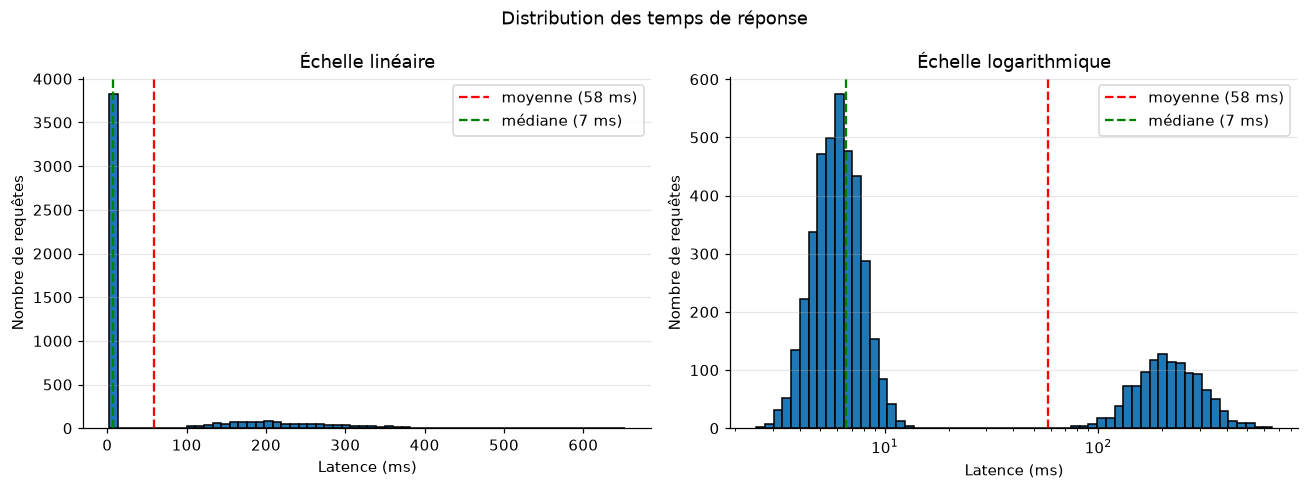

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Échelle linéaire
axes[0].hist(df4["latence_ms"], bins=60, edgecolor="black")
axes[0].set_title("Échelle linéaire")

# Échelle logarithmique
bins_log = np.logspace(np.log10(df4["latence_ms"].min()),
                       np.log10(df4["latence_ms"].max()), 60)
axes[1].hist(df4["latence_ms"], bins=bins_log, edgecolor="black")
axes[1].set_xscale("log")
axes[1].set_title("Échelle logarithmique")

for ax in axes:
    ax.axvline(moyenne, color="red", linestyle="--", label=f"moyenne ({moyenne:.0f} ms)")
    ax.axvline(mediane, color="green", linestyle="--", label=f"médiane ({mediane:.0f} ms)")
    ax.set_xlabel("Latence (ms)")
    ax.set_ylabel("Nombre de requêtes")
    ax.legend()

plt.suptitle("Distribution des temps de réponse")
plt.tight_layout()
plt.savefig("fig_q4_2.png", dpi=200)
plt.show()

>*Le graphique d'echelle lineaire montre un ecrasement de donnees sur la gauche, la distribution est fortement etale a droite(sommet ecrase pres de zero), la mediane se situant au centre du pic principal(7ms) et la moyenne deporte vers droite(58ms).Par contre, le graphe a l'echelle logarithmique devoile une segregation en plusieurs modes, on peut distinguer trois groupes  de latence (un ultra rapide a envrons 5 ms, un groupe rapide intermedoiaire entre 10-20 ms et un troisieme groupe lent entre 100ms et plus.On conclue donc que la piremiere  représentation linéaire s'avère inefficace, car elle masque complètement la structure interne des temps de réponse de l'immense majorité des utilisateurs.*

### 4.3 : explication de la forme par les autres colonnes

On examine chaque piste séparément (endpoint, version, heure) en comparant le nombre de requêtes, la moyenne et la médiane de chaque groupe. Une piste est retenue si les groupes ont des latences très différentes, et écartée si les latences sont semblables d'un groupe à l'autre.

In [45]:
# Piste 1 : le point d'entrée (endpoint)
par_endpoint = df4.groupby("endpoint")["latence_ms"].agg(["count", "mean", "median"]).round(1)
par_endpoint

,count,mean,median
endpoint,,,
/api/panier,1745,59.4,6.6
/api/profil,1607,59.5,6.6
/api/recherche,1648,55.9,6.6


In [46]:
# Piste 2 : la version du service (version_service)
par_version = df4.groupby("version_service")["latence_ms"].agg(["count", "mean", "median"]).round(1)
par_version

,count,mean,median
version_service,,,
2.3.1,4028,31.6,6.3
2.4.0,972,168.5,183.6


In [47]:
# Piste 3 : l'heure de la journée (extraite de horodatage)
df4["heure"] = df4["horodatage"].dt.hour
par_heure = df4.groupby("heure")["latence_ms"].agg(["count", "mean", "median"]).round(1)
par_heure

,count,mean,median
heure,,,
8,665,57.5,6.5
9,579,59.4,6.6
10,634,55.7,6.6
11,565,59.7,6.7
12,672,58.6,6.5
13,617,54.9,6.6
14,606,65.8,6.8
15,662,55.1,6.7


#### Vérification croisée : endpoint × version
On vérifie que l'effet d'une variable ne cache pas l'autre : la répartition des endpoints est-elle la même dans chaque version ? La médiane de chaque endpoint change-t-elle selon la version ?

In [48]:
print("Effectifs (nombre de requêtes) :")
print(pd.crosstab(df4["endpoint"], df4["version_service"]), "\n")

print("Médiane de latence (ms) :")
print(df4.pivot_table(values="latence_ms", index="endpoint",
                      columns="version_service", aggfunc="median").round(1))

Effectifs (nombre de requêtes) :
version_service  2.3.1  2.4.0
endpoint                     
/api/panier       1398    347
/api/profil       1303    304
/api/recherche    1327    321 

Médiane de latence (ms) :
version_service  2.3.1  2.4.0
endpoint                     
/api/panier        6.3  183.9
/api/profil        6.3  183.2
/api/recherche     6.2  184.1


*Pour la piste par endpoint, ont obtient que la repartion des requetes est homogene; la moyenne se situe entre 55,9 et 59,5ms et la mediane est a 6,6ms, cette piste a donc ete ecarte car la nature de la requete n'explique pas les differences de perfomance.Pour le parametre de l'heure, de 8 a 15heures, les valeurs restent egalement stables, la moyenne se situe entre 54.9 et 65.8 tandis que la mediane reste au alentours de 6.5, ce qui nous amene a conclure que l'heure de la journee n'est pas un parametre qui influence la latence. Par contre, en analysant les valeurs de la piste par version de service, on obtient un ecart importants entre les parametre de les donnees obtenu pour la version 2.3.1 (moyenne=31.6, mediane=6.3) et la version 2.4.0 (168.5ms, 183.6ms), ces resultats nous devoile que la structure multimodale observée sur l'histogramme s'explique intégralement par une régression majeure de performance introduite dans la version 2.4.0. La verification croisee endpoint x version service permet de confirmer que pour chaque point d'entree, la moyenne de temps de latence pour les requete effectues sous la version 2.3.1 est nettement plus petite que les requetes effectues sous version 2.4.0, ce qui conclu que la version 2.3.1 est la version la plus performante.*

### 4.4 : choix d'un indicateur à surveiller

Le tableau compare les indicateurs possibles sur l'ensemble des requêtes. 

In [49]:
indicateurs = pd.Series({
    "moyenne": df4["latence_ms"].mean(),
    "médiane (50e centile)": df4["latence_ms"].median(),
    "90e centile": df4["latence_ms"].quantile(0.90),
    "95e centile": df4["latence_ms"].quantile(0.95),
    "99e centile": df4["latence_ms"].quantile(0.99),
    "maximum": df4["latence_ms"].max(),
}).round(1)
indicateurs.to_frame("latence (ms)")

,latence (ms)
moyenne,58.2
médiane (50e centile),6.6
90e centile,227.5
95e centile,288.1
99e centile,384.1
maximum,653.1


*Pour surveiller ce service web, il est recommandé de choisir le 95e centile (288,1 ms) car cet indicateur standard de l'industrie est sensible aux ralentissements de la version 2.4.0 sans être perturbé par les valeurs maximales isolées, contrairement à une moyenne ou une médiane qui masquent la réalité de la distribution.*